# CytoFM Diverse-10 Selection

For each class (Benign, Malignant, Suspicious) we:
1. Extract 768-dim CLS-token embeddings for **all** images using the CytoFM backbone.
2. Run k-means (k = 10) in embedding space.
3. Pick the image whose embedding is closest to each cluster centroid.
4. Display the 10 most-diverse representatives as a 2 × 5 contact sheet.

Embeddings are cached to `.npy` files so re-runs are instant.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from torchvision import transforms
from sklearn.cluster import KMeans

SEED    = 42
K       = 10
CLASSES = ["Benign", "Malignant", "Suspicious"]

ROOT     = Path("../../..")
DATA_DIR = ROOT / "data/raw/AnnotatedDataSet"
CKPT     = ROOT / "models/cytofm_weights.pth"
OUT_DIR  = Path(".")   # save contact sheets alongside this notebook

sys.path.insert(0, str(ROOT))

device = torch.device("mps"  if torch.backends.mps.is_available()  else
                      "cuda" if torch.cuda.is_available()            else "cpu")
print(f"Device: {device}")

Device: mps


In [2]:
from src.models.architectures.cytofm import load_cytofm

backbone = load_cytofm(str(CKPT), device)
backbone.eval()
print(f"Backbone loaded — embed_dim: {backbone.embed_dim}")

Backbone loaded — embed_dim: 768


In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

def embed_all(class_dir: Path, cache_path: Path, batch_size: int = 32):
    """Return (paths, embeddings). Loads from cache if available."""
    paths = sorted(class_dir.glob("*.png"))
    if cache_path.exists():
        print(f"  Loading cached embeddings from {cache_path.name}")
        embs = np.load(cache_path)
        return paths, embs

    print(f"  Embedding {len(paths)} images …")
    all_embs = []
    for i in range(0, len(paths), batch_size):
        batch = paths[i : i + batch_size]
        tensors = torch.stack([
            transform(Image.open(p).convert("RGB")) for p in batch
        ]).to(device)
        with torch.no_grad():
            embs = backbone(tensors).cpu().float().numpy()
        all_embs.append(embs)
        if (i // batch_size) % 10 == 0:
            print(f"    {i + len(batch)}/{len(paths)}", end="\r")
    print()

    embs = np.concatenate(all_embs, axis=0)
    np.save(cache_path, embs)
    print(f"  Cached → {cache_path.name}")
    return paths, embs


def select_diverse(paths, embs, k=K, seed=SEED):
    """K-means in embedding space; return (selected_paths, cluster_ids)."""
    km = KMeans(n_clusters=k, random_state=seed, n_init="auto")
    km.fit(embs)
    selected, cluster_ids = [], []
    for c in range(k):
        centroid = km.cluster_centers_[c]          # (768,)
        mask     = km.labels_ == c
        indices  = np.where(mask)[0]
        dists    = np.linalg.norm(embs[indices] - centroid, axis=1)
        best     = indices[np.argmin(dists)]
        selected.append(paths[best])
        cluster_ids.append(c + 1)
    return selected, cluster_ids

In [4]:
CLASS_COLORS = {
    "Benign":     "#4caf7d",
    "Malignant":  "#e07b54",
    "Suspicious": "#f0c040",
}
BG = "#1a1a1a"

def make_contact_sheet(selected_paths, cluster_ids, class_name, save_path):
    """2 rows × 5 cols contact sheet of the 10 diverse images."""
    accent = CLASS_COLORS[class_name]
    fig = plt.figure(figsize=(20, 9), facecolor=BG)
    fig.suptitle(
        f"{class_name} — 10 Most Diverse Images (CytoFM + k-means, k={K})",
        color="white", fontsize=15, fontweight="bold", y=1.01,
    )

    gs = gridspec.GridSpec(2, 5, figure=fig, hspace=0.12, wspace=0.06)

    for idx, (path, cid) in enumerate(zip(selected_paths, cluster_ids)):
        row, col = divmod(idx, 5)
        ax = fig.add_subplot(gs[row, col])

        img = Image.open(path).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"Cluster {cid}", color=accent, fontsize=10, fontweight="bold", pad=4)
        ax.axis("off")

        # thin coloured border
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor(accent)
            spine.set_linewidth(1.5)

    plt.savefig(save_path, dpi=150, bbox_inches="tight", facecolor=BG)
    plt.show()
    print(f"Saved: {save_path}")


Benign
  Embedding 1236 images …
    992/1236
  Cached → embeddings_benign.npy
  Embeddings shape: (1236, 768)


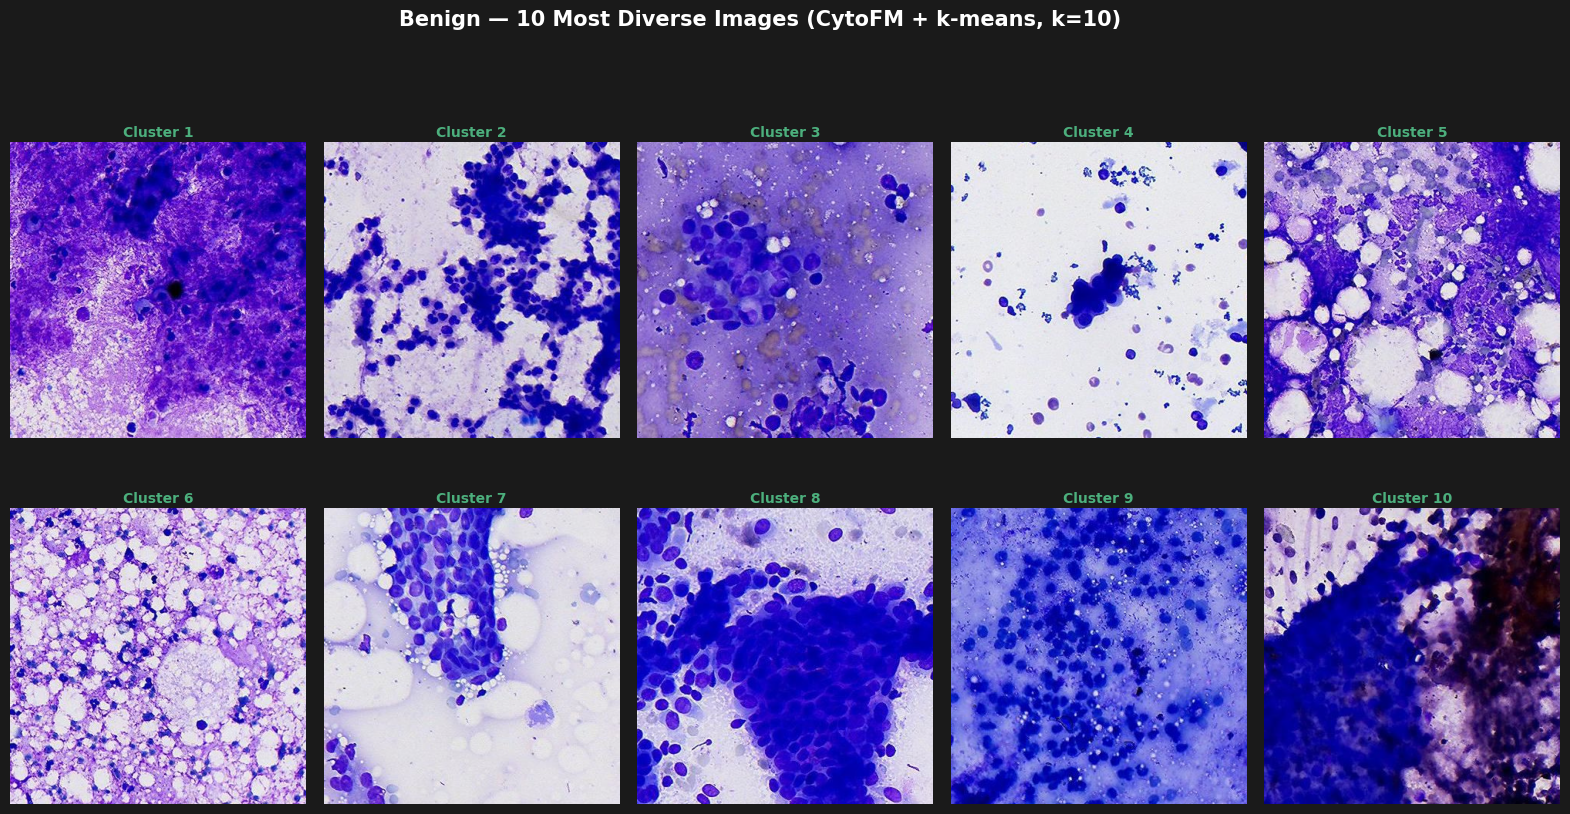

Saved: diverse_10_benign.png

Malignant
  Embedding 1734 images …
    1632/1734
  Cached → embeddings_malignant.npy
  Embeddings shape: (1734, 768)


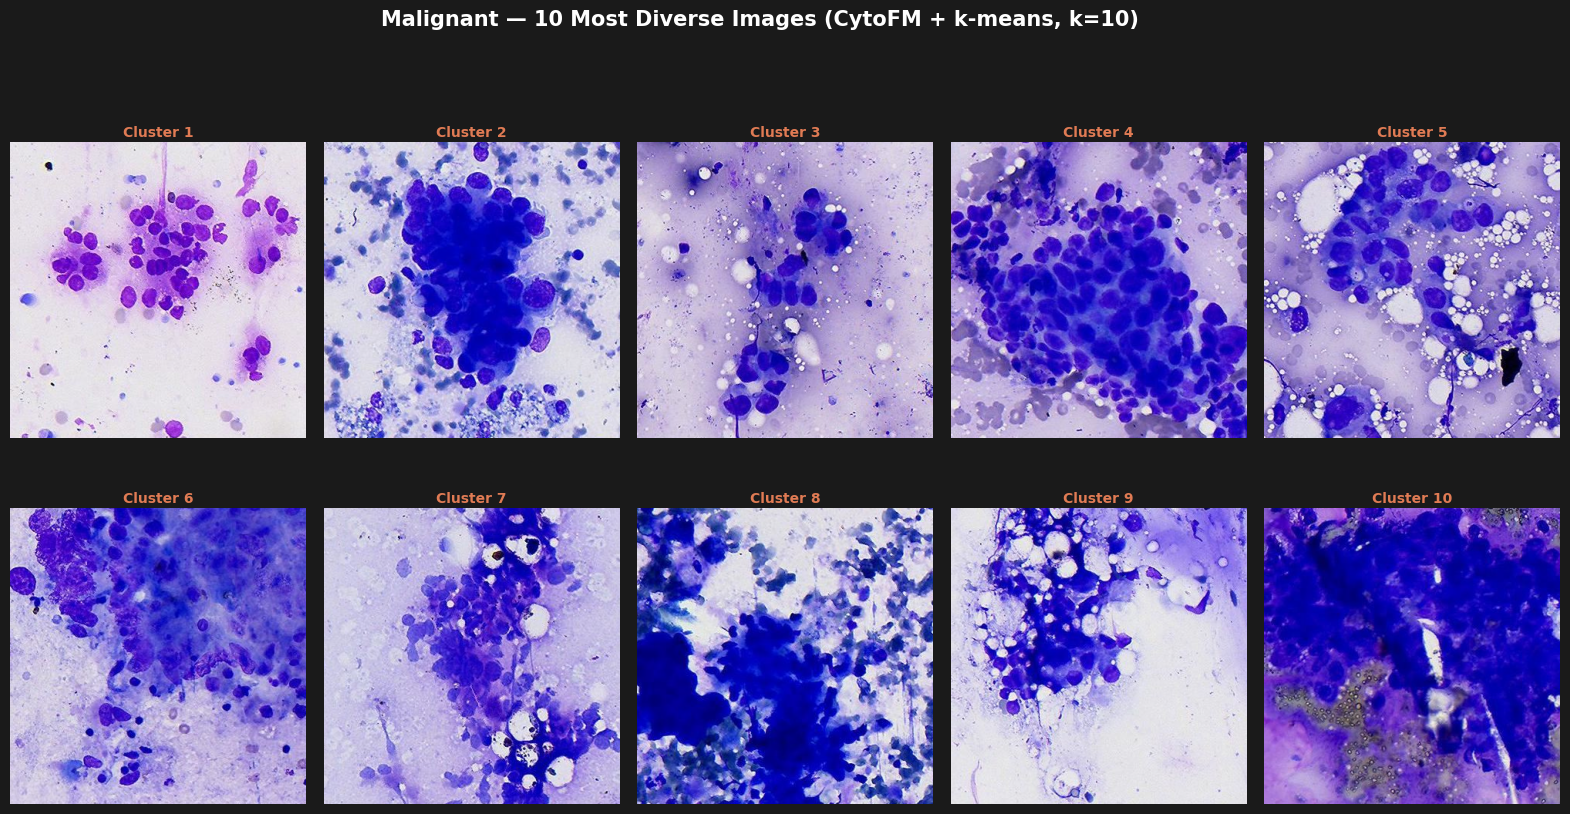

Saved: diverse_10_malignant.png

Suspicious
  Embedding 1832 images …
    1632/1832
  Cached → embeddings_suspicious.npy
  Embeddings shape: (1832, 768)


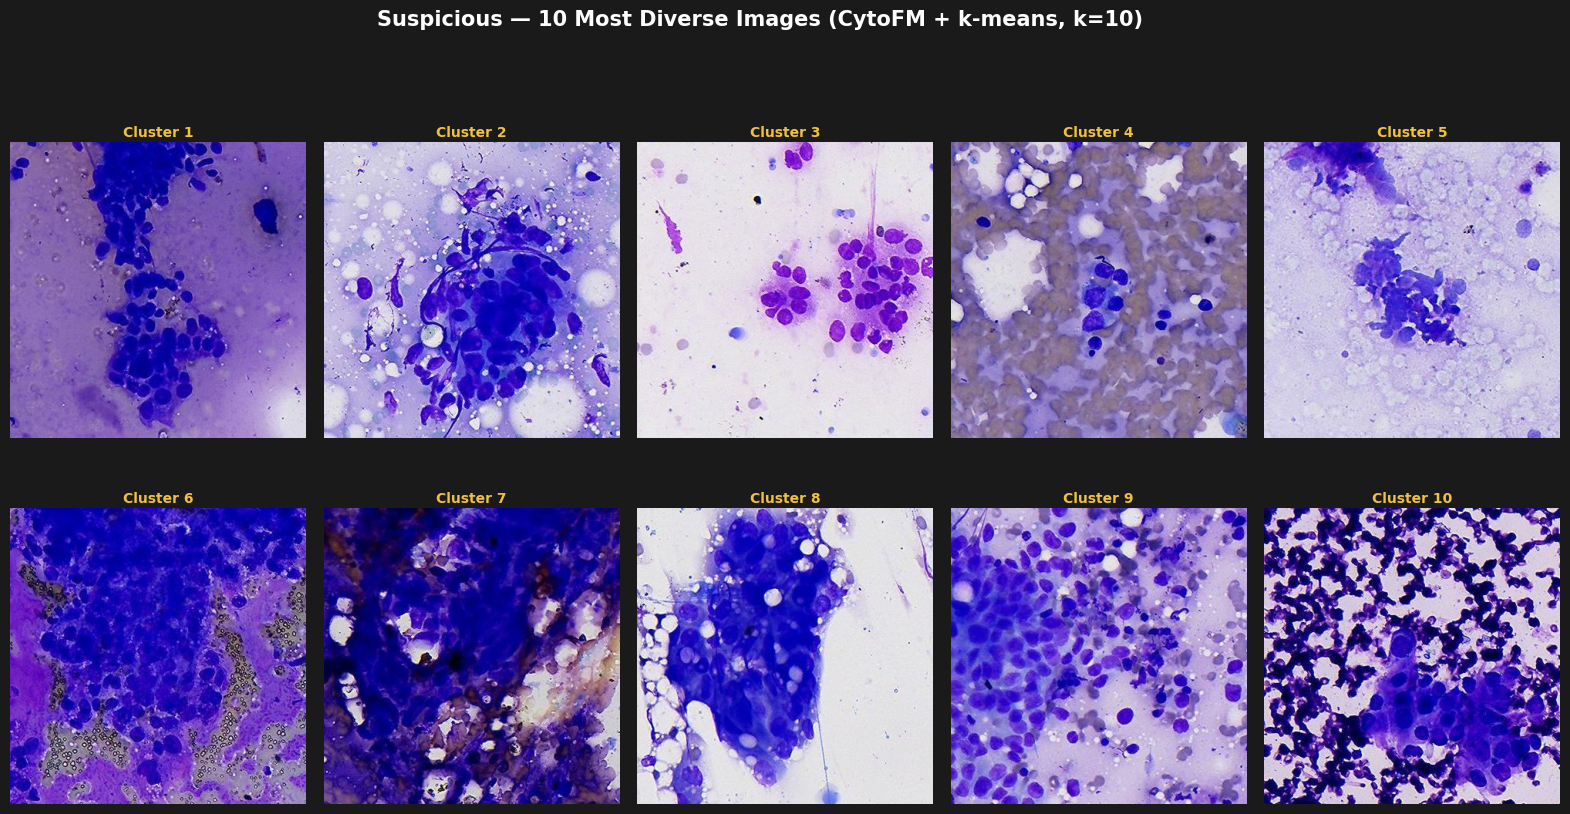

Saved: diverse_10_suspicious.png

Done.


In [5]:
results = {}

for cls in CLASSES:
    print(f"\n{'='*50}\n{cls}")
    class_dir  = DATA_DIR / cls
    cache_path = OUT_DIR / f"embeddings_{cls.lower()}.npy"

    paths, embs = embed_all(class_dir, cache_path)
    print(f"  Embeddings shape: {embs.shape}")

    selected, cluster_ids = select_diverse(paths, embs)
    results[cls] = {"paths": selected, "cluster_ids": cluster_ids}

    save_path = OUT_DIR / f"diverse_10_{cls.lower()}.png"
    make_contact_sheet(selected, cluster_ids, cls, save_path)

print("\nDone.")

In [6]:
# Summary table — filenames for each selected image
for cls in CLASSES:
    print(f"\n{cls}")
    for cid, p in zip(results[cls]["cluster_ids"], results[cls]["paths"]):
        print(f"  Cluster {cid:2d}: {p.name}")


Benign
  Cluster  1: C1496-22-2_lux_37645_luy_44068_h_91_w_91_padded_384.png
  Cluster  2: C1930-23-1_lux_26043_luy_63868_h_88_w_88_padded_384.png
  Cluster  3: C1908-22-1_lux_28857_luy_36306_h_96_w_96_padded_384.png
  Cluster  4: 2025-04-16T21-37-15-529Z-C1432-23-1.tif_lux_14747_luy_33195_h_109_w_109.png
  Cluster  5: C1357-22-1_lux_10874_luy_57767_h_93_w_93_padded_384.png
  Cluster  6: 2025-04-16T21-38-19-717Z-C1131-23-2.tif_lux_31818_luy_26942_h_287_w_258.png
  Cluster  7: C501-22-1_lux_29762_luy_75913_h_92_w_92_padded_384.png
  Cluster  8: C1102-23-1_lux_21311_luy_7223_h_135_w_250_padded_384.png
  Cluster  9: C410-22-1_lux_29225_luy_53659_h_109_w_109_padded_384.png
  Cluster 10: FNAC87-21-1_lux_25130_luy_78861_h_127_w_127_padded_384.png

Malignant
  Cluster  1: C1405-22-1_lux_28867_luy_39380_h_98_w_98_padded_384.png
  Cluster  2: C775-22-2_lux_10471_luy_23100_h_373_w_504_padded_384.png
  Cluster  3: C857-22-1_lux_19733_luy_57401_h_101_w_101_padded_384.png
  Cluster  4: C804-22-1_l